PyTorch: 2.13.0+cpu
CUDA available: False

Total patients: 112
Sample folders: ['data.csv', 'README.md', 'TCGA_CS_4941_19960909']

Total image-mask pairs: 3929

Image shape: (256, 256, 3)
Mask shape:  (256, 256)
Mask unique values: [  0 255]
Tumour pixels: 4681
Total pixels:  65536


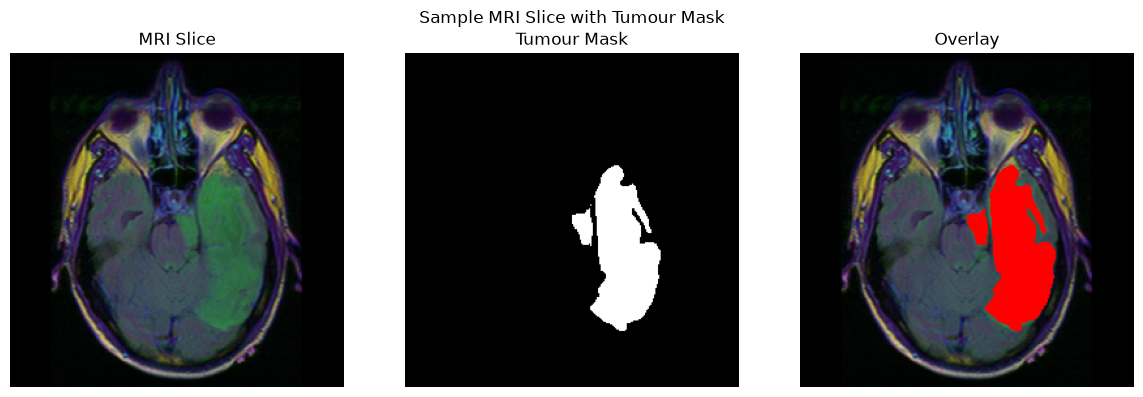


Dataset verified!


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# explore dataset structure
data_path = '../data/kaggle_3m'
patients   = os.listdir(data_path)
print(f"\nTotal patients: {len(patients)}")
print(f"Sample folders: {patients[:3]}")

# count all image and mask pairs
images = []
masks  = []

for patient in patients:
    patient_path = os.path.join(data_path, patient)
    if not os.path.isdir(patient_path):
        continue
    for fname in os.listdir(patient_path):
        if fname.endswith('.tif') and 'mask' not in fname:
            img_path  = os.path.join(patient_path, fname)
            mask_path = img_path.replace('.tif', '_mask.tif')
            if os.path.exists(mask_path):
                images.append(img_path)
                masks.append(mask_path)

print(f"\nTotal image-mask pairs: {len(images)}")

# load and display one sample
img  = cv2.imread(images[100])
mask = cv2.imread(masks[100], cv2.IMREAD_GRAYSCALE)

print(f"\nImage shape: {img.shape}")
print(f"Mask shape:  {mask.shape}")
print(f"Mask unique values: {np.unique(mask)}")
print(f"Tumour pixels: {np.sum(mask > 0)}")
print(f"Total pixels:  {mask.size}")

# visualise
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title('MRI Slice')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Tumour Mask')
axes[1].axis('off')

overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
overlay[mask > 0] = [255, 0, 0]
axes[2].imshow(overlay)
axes[2].set_title('Overlay')
axes[2].axis('off')

plt.suptitle('Sample MRI Slice with Tumour Mask', fontsize=12)
plt.tight_layout()
plt.savefig('../data/sample_visualisation.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("\nDataset verified!")

In [3]:
# check how many slices actually have tumour vs no tumour
has_tumour    = 0
no_tumour     = 0
tumour_pixels = []

for mask_path in masks[:200]:
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if np.sum(m > 0) > 0:
        has_tumour += 1
        tumour_pixels.append(np.sum(m > 0) / m.size * 100)
    else:
        no_tumour += 1

print(f"Checked first 200 slices:")
print(f"  With tumour:    {has_tumour}")
print(f"  Without tumour: {no_tumour}")
print(f"  Tumour ratio:   {has_tumour/200*100:.1f}%")
print()
print(f"Among slices with tumour:")
print(f"  Mean tumour area: {np.mean(tumour_pixels):.2f}% of slice")
print(f"  Max tumour area:  {np.max(tumour_pixels):.2f}% of slice")
print(f"  Min tumour area:  {np.min(tumour_pixels):.2f}% of slice")

Checked first 200 slices:
  With tumour:    66
  Without tumour: 134
  Tumour ratio:   33.0%

Among slices with tumour:
  Mean tumour area: 3.30% of slice
  Max tumour area:  9.44% of slice
  Min tumour area:  0.11% of slice


In [4]:
import sys
sys.path.insert(0, '..')
import torch
from src.model import UNet

model = UNet(in_channels=3, out_channels=1)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

# test forward pass with dummy input
dummy_input = torch.randn(2, 3, 256, 256)
output      = model(dummy_input)

print(f"Input shape:  {dummy_input.shape}")
print(f"Output shape: {output.shape}")
print(f"Output range: {output.min():.3f} to {output.max():.3f}")
print("\nU-Net built successfully!")

Total parameters: 31,037,633
Input shape:  torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])
Output range: -1.124 to 1.897

U-Net built successfully!


Train samples: 3143
Val samples:   786

Batch image shape: torch.Size([8, 3, 256, 256])
Batch mask shape:  torch.Size([8, 1, 256, 256])
Image range:       -2.118 to 2.131
Mask unique vals:  tensor([0., 1.])


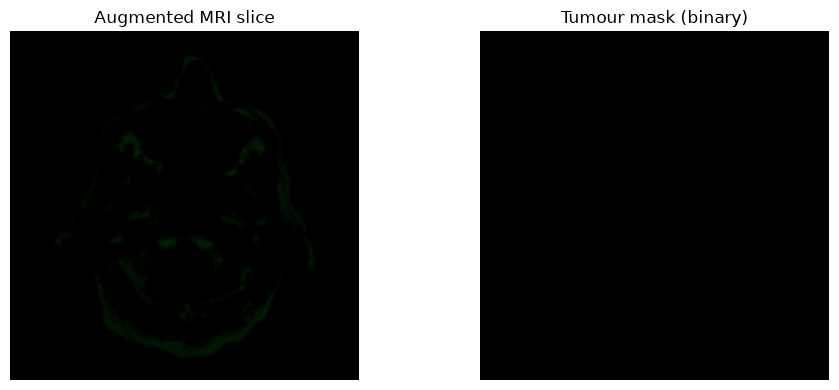


dataset.py working correctly!


In [5]:
import sys
sys.path.insert(0, '..')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from src.dataset import BrainMRIDataset

# reuse images and masks from earlier cell
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    images, masks,
    test_size=0.2,
    random_state=42
)

print(f"Train samples: {len(train_imgs)}")
print(f"Val samples:   {len(val_imgs)}")

# create datasets
train_dataset = BrainMRIDataset(train_imgs, train_masks,
                                 img_size=256, augment=True)
val_dataset   = BrainMRIDataset(val_imgs, val_masks,
                                 img_size=256, augment=False)

# create dataloaders
train_loader = DataLoader(train_dataset, batch_size=8,
                          shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=8,
                          shuffle=False, num_workers=0)

# check one batch
imgs, masks_batch = next(iter(train_loader))
print(f"\nBatch image shape: {imgs.shape}")
print(f"Batch mask shape:  {masks_batch.shape}")
print(f"Image range:       {imgs.min():.3f} to {imgs.max():.3f}")
print(f"Mask unique vals:  {masks_batch.unique()}")

# visualise one augmented sample
img_show  = imgs[0].permute(1, 2, 0).numpy()
mask_show = masks_batch[0].squeeze().numpy()

# denormalise for display
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
img_show = (img_show * std + mean).clip(0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_show)
axes[0].set_title('Augmented MRI slice')
axes[0].axis('off')
axes[1].imshow(mask_show, cmap='gray')
axes[1].set_title('Tumour mask (binary)')
axes[1].axis('off')
plt.tight_layout()
plt.savefig('../data/augmented_sample.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("\ndataset.py working correctly!")

In [6]:
import sys
sys.path.insert(0, '..')
import torch
from src.evaluate import dice_coefficient, iou_score, dice_loss

# simulate perfect prediction
pred_perfect = torch.ones(1, 1, 256, 256) * 10.0
target       = torch.ones(1, 1, 256, 256)

dice = dice_coefficient(pred_perfect, target)
iou  = iou_score(pred_perfect, target)
loss = dice_loss(pred_perfect, target)

print("Perfect prediction:")
print(f"  Dice coefficient: {dice:.4f}")
print(f"  IoU score:        {iou:.4f}")
print(f"  Dice loss:        {loss:.4f}")

# simulate wrong prediction
pred_wrong = torch.ones(1, 1, 256, 256) * -10.0

dice = dice_coefficient(pred_wrong, target)
iou  = iou_score(pred_wrong, target)
loss = dice_loss(pred_wrong, target)

print("\nCompletely wrong prediction:")
print(f"  Dice coefficient: {dice:.4f}")
print(f"  IoU score:        {iou:.4f}")
print(f"  Dice loss:        {loss:.4f}")

print("\nevaluate.py working correctly!")

Perfect prediction:
  Dice coefficient: 1.0000
  IoU score:        1.0000
  Dice loss:        0.0000

Completely wrong prediction:
  Dice coefficient: 0.0000
  IoU score:        0.0000
  Dice loss:        0.9999

evaluate.py working correctly!


In [7]:
import sys
sys.path.insert(0, '..')
from src.train import train

# use only 100 images for quick local test
small_imgs  = images[:100]
small_masks = masks[:100]

model, history = train(
    image_paths = small_imgs,
    mask_paths  = small_masks,
    epochs      = 2,
    batch_size  = 4,
    lr          = 1e-4,
    img_size    = 256,
    save_path   = '../models/best_model.pth'
)

print("\nHistory:")
for h in history:
    print(h)

Training on: cpu
Epochs:      2
Batch size:  4
LR:          0.0001

Train samples: 80
Val samples:   20
Epoch   1/2 | train_loss: 0.9445 | train_dice: 0.1172 | val_loss: 0.9889 | val_dice: 0.0804 | val_iou: 0.0437
  → best model saved (val_dice=0.0804)
Epoch   2/2 | train_loss: 0.9277 | train_dice: 0.3077 | val_loss: 0.9795 | val_dice: 0.1408 | val_iou: 0.0816
  → best model saved (val_dice=0.1408)

Training complete. Best val_dice: 0.1408
Model saved to: ../models/best_model.pth

History:
{'epoch': 1, 'train_loss': 0.9445, 'train_dice': 0.1172, 'val_loss': 0.9889, 'val_dice': 0.0804, 'val_iou': 0.0437}
{'epoch': 2, 'train_loss': 0.9277, 'train_dice': 0.3077, 'val_loss': 0.9795, 'val_dice': 0.1408, 'val_iou': 0.0816}


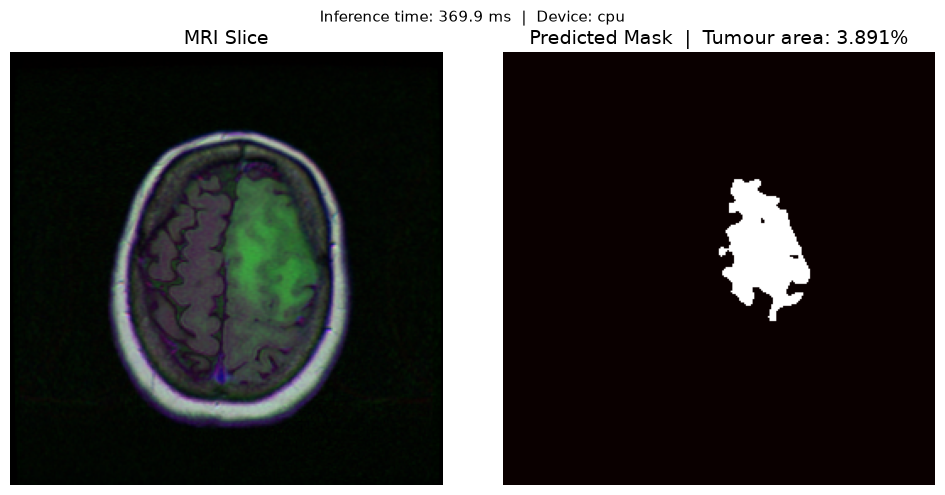

In [8]:
import base64, requests, io
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# ── your image path ──────────────────────────────────────────
image_path = r"D:\Master in IB&IV\ML Projects\brain-tumour-segmentation\data\kaggle_3m\TCGA_DU_7010_19860307\TCGA_DU_7010_19860307_45.tif"

# ── encode and send to API ───────────────────────────────────
with open(image_path, "rb") as f:
    image_b64 = base64.b64encode(f.read()).decode("utf-8")

response = requests.post(
    "http://localhost:8000/predict",
    json={"image_b64": image_b64, "threshold": 0.5}
)
data = response.json()

# ── decode the predicted mask ────────────────────────────────
mask_bytes = base64.b64decode(data['mask_b64'])
mask_img   = Image.open(io.BytesIO(mask_bytes))

# ── display side by side ─────────────────────────────────────
original = Image.open(image_path).convert("RGB").resize((256, 256))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title("MRI Slice", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask_img, cmap="hot")
axes[1].set_title(f"Predicted Mask  |  Tumour area: {data['tumour_area_pct']}%", fontsize=14)
axes[1].axis("off")

plt.suptitle(f"Inference time: {data['inference_ms']} ms  |  Device: {data['device']}", fontsize=11)
plt.tight_layout()
plt.show()

Found 10 tumour-positive slices
Slice 1 done — tumour area: 2.0538%  inference: 351.97ms
Slice 2 done — tumour area: 3.3447%  inference: 343.82ms
Slice 3 done — tumour area: 4.3015%  inference: 335.07ms
Slice 4 done — tumour area: 3.5477%  inference: 367.42ms
Slice 5 done — tumour area: 1.9241%  inference: 344.72ms
Slice 6 done — tumour area: 2.0218%  inference: 335.33ms
Slice 7 done — tumour area: 0.7431%  inference: 340.37ms
Slice 8 done — tumour area: 0.0%  inference: 341.12ms
Slice 9 done — tumour area: 2.0798%  inference: 328.66ms
Slice 10 done — tumour area: 2.3865%  inference: 323.89ms


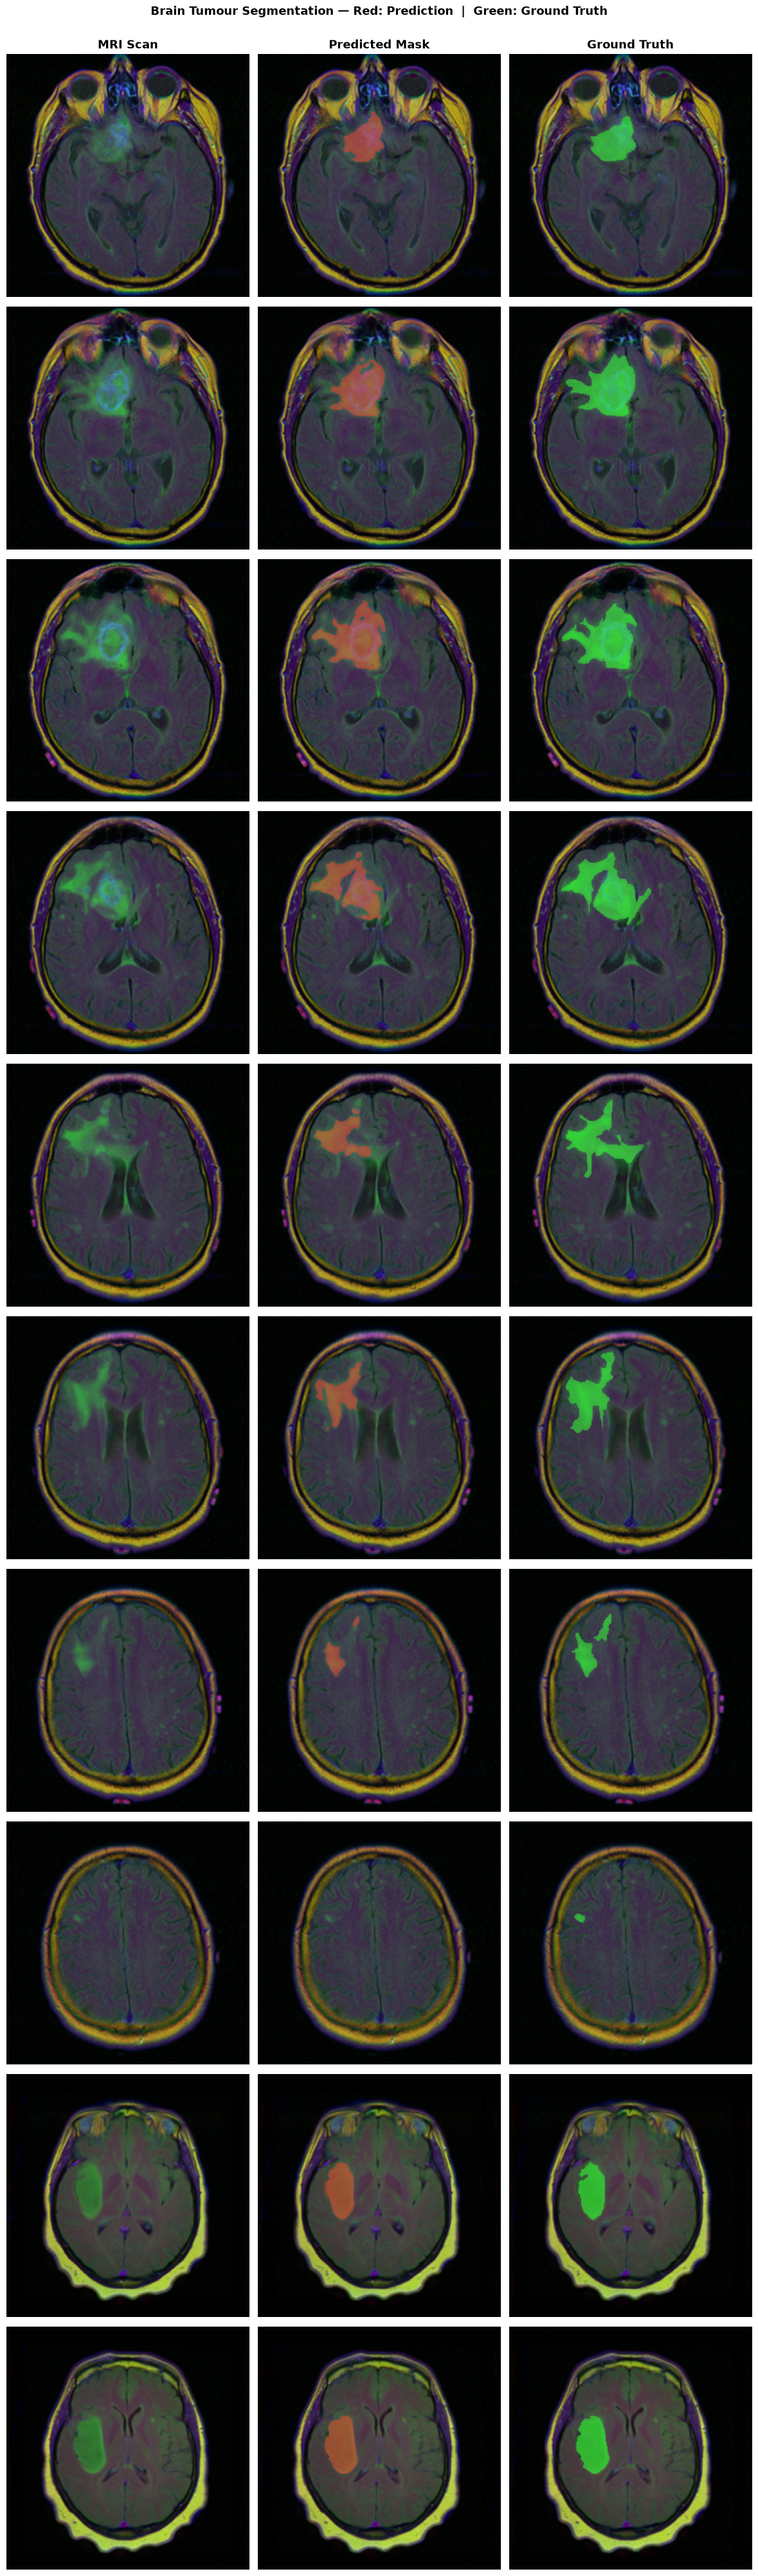

In [9]:
import base64, requests, io, os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# ── find 10 image/mask pairs from your dataset ───────────────
data_root = r"D:\Master in IB&IV\ML Projects\brain-tumour-segmentation\data\kaggle_3m"

image_paths = []
mask_paths  = []

for patient in sorted(os.listdir(data_root)):
    patient_dir = os.path.join(data_root, patient)
    if not os.path.isdir(patient_dir):
        continue
    for f in sorted(os.listdir(patient_dir)):
        if f.endswith('.tif') and 'mask' not in f:
            img_p = os.path.join(patient_dir, f)
            msk_p = img_p.replace('.tif', '_mask.tif')
            if os.path.exists(msk_p):
                # only pick slices that have a tumour
                gt = np.array(Image.open(msk_p).convert('L'))
                if gt.max() > 0:
                    image_paths.append(img_p)
                    mask_paths.append(msk_p)
        if len(image_paths) >= 10:
            break
    if len(image_paths) >= 10:
        break

print(f"Found {len(image_paths)} tumour-positive slices")

# ── run inference on all 10 ──────────────────────────────────
fig, axes = plt.subplots(10, 3, figsize=(12, 40))

col_titles = ['MRI Scan', 'Predicted Mask', 'Ground Truth']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=13, fontweight='bold')

for i, (img_p, msk_p) in enumerate(zip(image_paths, mask_paths)):

    # encode and send to API
    with open(img_p, "rb") as f:
        image_b64 = base64.b64encode(f.read()).decode("utf-8")

    response = requests.post(
        "http://localhost:8000/predict",
        json={"image_b64": image_b64, "threshold": 0.5}
    )
    data = response.json()

    # decode predicted mask
    mask_bytes = base64.b64decode(data['mask_b64'])
    pred_mask  = np.array(Image.open(io.BytesIO(mask_bytes)))

    # load originals
    original = np.array(Image.open(img_p).convert("RGB").resize((256, 256)))
    gt_mask  = np.array(Image.open(msk_p).convert("L").resize((256, 256), Image.NEAREST))

    # column 0 — MRI
    axes[i, 0].imshow(original)
    axes[i, 0].axis("off")
    axes[i, 0].set_ylabel(f"slice {i+1}\n{data['tumour_area_pct']}%", fontsize=8)

    # column 1 — predicted mask
    axes[i, 1].imshow(original)
    pred_overlay = np.zeros((*pred_mask.shape, 4), dtype=np.float32)
    pred_overlay[pred_mask > 0] = [1.0, 0.2, 0.2, 0.5]   # red
    axes[i, 1].imshow(pred_overlay)
    axes[i, 1].axis("off")

    # column 2 — ground truth
    axes[i, 2].imshow(original)
    gt_overlay = np.zeros((*gt_mask.shape, 4), dtype=np.float32)
    gt_overlay[gt_mask > 0] = [0.2, 1.0, 0.2, 0.5]       # green
    axes[i, 2].imshow(gt_overlay)
    axes[i, 2].axis("off")

    print(f"Slice {i+1} done — tumour area: {data['tumour_area_pct']}%  inference: {data['inference_ms']}ms")

plt.suptitle("Brain Tumour Segmentation — Red: Prediction  |  Green: Ground Truth",
             fontsize=13, fontweight='bold', y=1.001)
plt.tight_layout()
plt.show()

Tumour area  : 3.4546 %
Inference    : 365.11 ms


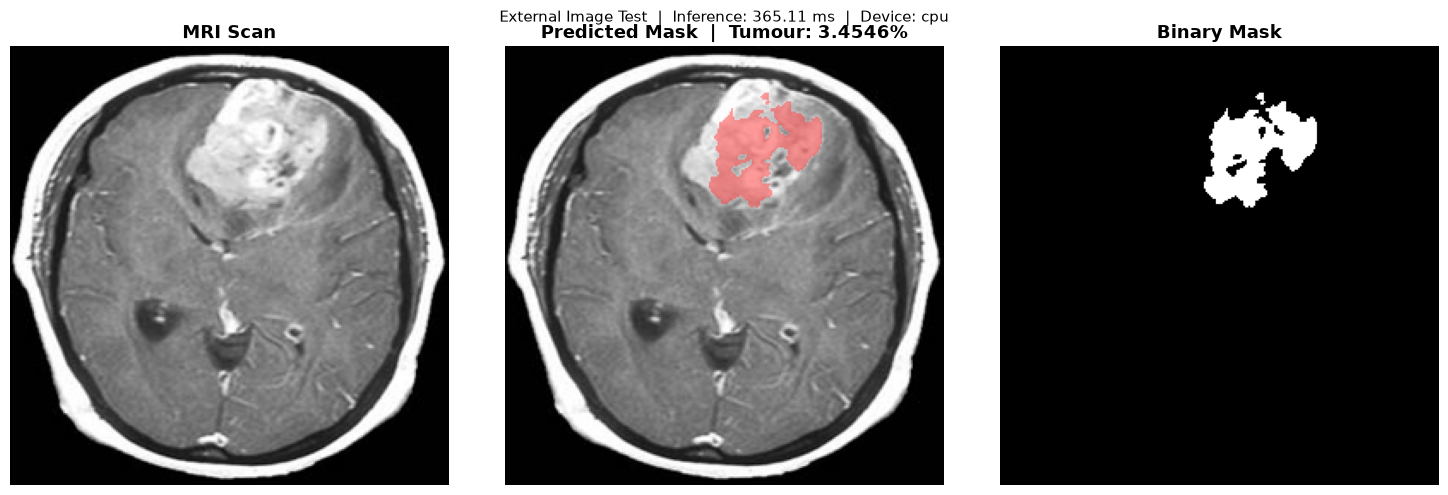

In [10]:
import base64, requests, io
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np


image_path = r"D:\Master in IB&IV\ML Projects\brain-tumour-segmentation\data\Y13.jpg"


with open(image_path, "rb") as f:
    image_b64 = base64.b64encode(f.read()).decode("utf-8")

response = requests.post(
    "http://localhost:8000/predict",
    json={"image_b64": image_b64, "threshold": 0.5}
)
data = response.json()
print(f"Tumour area  : {data['tumour_area_pct']} %")
print(f"Inference    : {data['inference_ms']} ms")

# ── decode predicted mask ────────────────────────────────────
mask_bytes = base64.b64decode(data['mask_b64'])
pred_mask  = np.array(Image.open(io.BytesIO(mask_bytes)))

# ── load and resize original ─────────────────────────────────
original = np.array(Image.open(image_path).convert("RGB").resize((256, 256)))

# ── visualise ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# column 1 — original MRI
axes[0].imshow(original)
axes[0].set_title("MRI Scan", fontsize=13, fontweight='bold')
axes[0].axis("off")

# column 2 — prediction overlay (red)
axes[1].imshow(original)
pred_overlay = np.zeros((*pred_mask.shape, 4), dtype=np.float32)
pred_overlay[pred_mask > 0] = [1.0, 0.2, 0.2, 0.5]
axes[1].imshow(pred_overlay)
axes[1].set_title(f"Predicted Mask  |  Tumour: {data['tumour_area_pct']}%", fontsize=13, fontweight='bold')
axes[1].axis("off")

# column 3 — raw binary mask
axes[2].imshow(pred_mask, cmap='gray')
axes[2].set_title("Binary Mask", fontsize=13, fontweight='bold')
axes[2].axis("off")

plt.suptitle(f"External Image Test  |  Inference: {data['inference_ms']} ms  |  Device: {data['device']}",
             fontsize=11)
plt.tight_layout()
plt.show()